# Классификация и регрессия с tslearn

Сравним расстояния, случайные свертки, признаки и нейросети на PowerCons, классификация использует все 144 точки, регрессия прогнозирует среднее следующих 24 точек по первым 120

Для каждого семейства обучим минимум три классификатора и три регрессора, параметры выбираем на одних и тех же 144 обучающих и 36 валидационных рядах, после выбора переобучаем на 180 TRAIN и оцениваем на 180 TEST

Основная библиотека — tslearn, дополнительные реализации указаны рядом с экспериментами

## Загрузка и анализ

[Официальный PowerCons](https://www.timeseriesclassification.com/description.php?Dataset=PowerCons): класс 1 соответствует теплому сезону, класс 2 — холодному, точка означает десятиминутное измерение потребления

In [1]:
import os
os.environ.setdefault('NUMBA_NUM_THREADS', '4')
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.grid': True, 'grid.alpha': .2})
ROOT = Path.cwd()
DATA = ROOT / 'data' / 'PowerCons'
DATA.mkdir(parents=True, exist_ok=True)
required = [f'PowerCons_{s}.txt' for s in ('TRAIN', 'TEST')]
if not all((DATA / f).exists() for f in required):
    url = 'https://www.timeseriesclassification.com/aeon-toolkit/PowerCons.zip'
    with urlopen(url, timeout=90) as response:
        archive = ZipFile(BytesIO(response.read()))
    for name in required:
        member = next(m for m in archive.namelist() if Path(m).name == name)
        (DATA / name).write_bytes(archive.read(member))
def load_split(name):
    a = np.loadtxt(DATA / f'PowerCons_{name}.txt')
    x, y = a[:, 1:].astype(np.float64), a[:, 0].astype(int)
    assert x.shape == (180, 144) and np.isfinite(x).all()
    assert set(y) == {1, 2}
    return x, y
X_train, y_train = load_split('TRAIN')
X_test, y_test = load_split('TEST')
fit_idx, val_idx = train_test_split(np.arange(180), test_size=.2,
    random_state=SEED, stratify=y_train)
display(pd.DataFrame({'TRAIN': pd.Series(y_train).value_counts(),
                      'TEST': pd.Series(y_test).value_counts()}).rename_axis('Класс'))
print('TRAIN:', X_train.shape, 'TEST:', X_test.shape,
      'fit / validation:', len(fit_idx), len(val_idx))

,TRAIN,TEST
Класс,,
1,90,90
2,90,90


TRAIN: (180, 144) TEST: (180, 144) fit / validation: 144 36


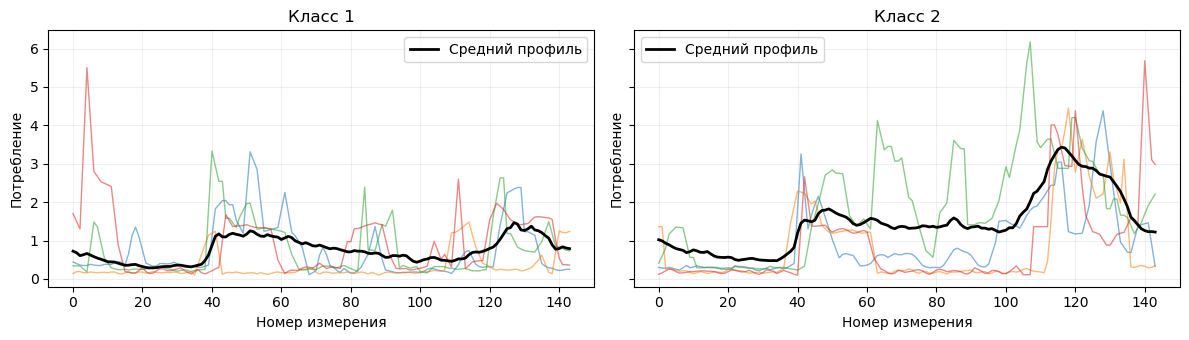

,Среднее,Стандартное отклонение,Минимум,Максимум
count,180.000,180.000,180.00,180.000
mean,1.114,0.909,0.20,4.196
std,0.517,0.302,0.09,1.447
min,0.320,0.260,0.04,1.380
25%,0.739,0.716,0.13,3.245
50%,0.998,0.902,0.22,4.305
75%,1.406,1.098,0.23,5.102
max,2.771,1.576,0.81,7.800


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for cls, ax in zip((1, 2), axes):
    rows = X_train[y_train == cls]
    for row in rows[:4]:
        ax.plot(row, alpha=.55, linewidth=1)
    ax.plot(rows.mean(axis=0), color='black', linewidth=2, label='Средний профиль')
    ax.set(title=f'Класс {cls}', xlabel='Номер измерения', ylabel='Потребление')
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Среднее': X_train.mean(1), 'Стандартное отклонение': X_train.std(1),
                      'Минимум': X_train.min(1), 'Максимум': X_train.max(1)}).describe().round(3))

## Регрессионная цель

Если полный ряд стандартизирован к нулевому среднему, среднее его хвоста равно минус пяти средним префикса, проверим это до обучения

У PowerCons средние рядов и масштабы различаются, поэтому эта тождественная связь не выполняется и оставляем среднее последних 24 точек в качестве цели, скрытый участок не участвует в нормализации входа

Средние TRAIN: 0.3199 ... 2.7713
Стандартные отклонения: 0.2599 ... 1.5760
Максимальная невязка предполагаемой связи y=-5*mean(prefix): 16.6279


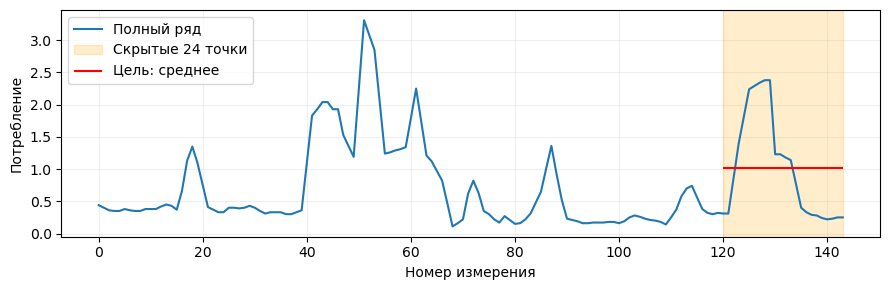

In [3]:
# Проверяем только TRAIN перед выбором регрессионной постановки
means, stds = X_train.mean(1), X_train.std(1)
identity_error = np.max(np.abs(X_train[:, 120:].mean(1) + 5*X_train[:, :120].mean(1)))
full_z = np.max(np.abs(means)) < 1e-6 and np.max(np.abs(stds-1)) < 1e-6
assert not full_z, 'Для z-нормализованных рядов нужно изменить цель на последнее значение'
print(f'Средние TRAIN: {means.min():.4f} ... {means.max():.4f}')
print(f'Стандартные отклонения: {stds.min():.4f} ... {stds.max():.4f}')
print(f'Максимальная невязка предполагаемой связи y=-5*mean(prefix): {identity_error:.4f}')
Xr_train, Xr_test = X_train[:, :120].copy(), X_test[:, :120].copy()
yr_train, yr_test = X_train[:, 120:].mean(1), X_test[:, 120:].mean(1)
assert Xr_train.shape == Xr_test.shape == (180, 120)
assert np.isfinite(yr_train).all() and np.isfinite(yr_test).all()
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(X_train[0], label='Полный ряд')
ax.axvspan(120, 143, alpha=.2, color='orange', label='Скрытые 24 точки')
ax.hlines(yr_train[0], 120, 143, color='red', label='Цель: среднее')
ax.set(xlabel='Номер измерения', ylabel='Потребление')
ax.legend()
plt.tight_layout()
plt.show()

## Подготовка экспериментов

Масштабируем вход одним средним и стандартным отклонением, рассчитанными только по обучаемой части, это сохраняет различия уровней между рядами

Для линейных моделей дополнительно масштабируем извлеченные признаки, ни один трансформер не обучается на TEST

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import FunctionTransformer
from aeon.transformations.collection.convolution_based import Rocket, MiniRocket
from aeon.transformations.collection.feature_based import SevenNumberSummary

class GlobalSeriesScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.mean_ = float(np.mean(X))
        self.scale_ = max(float(np.std(X)), 1e-8)
        return self
    def transform(self, X):
        return (np.asarray(X)-self.mean_)/self.scale_

class HydraNumpy(BaseEstimator, TransformerMixin):
    # Одномерный перенос алгоритма HYDRA: random kernels, dilations, competition
    # Источник алгоритма: aeon 1.3, _hydra.py, оригинал Angus Dempster
    # Это NumPy-реализация, не класс HydraTransformer из aeon
    def __init__(self, n_kernels=8, n_groups=16, random_state=42):
        self.n_kernels, self.n_groups, self.random_state = n_kernels, n_groups, random_state
    def fit(self, X, y=None):
        assert X.shape[1] == 1 and self.n_groups % 2 == 0
        self.dilations_ = 2**np.arange(int(np.log2((X.shape[2]-1)/8))+1)
        rng = np.random.default_rng(self.random_state)
        w = rng.normal(size=(len(self.dilations_), 2, self.n_groups//2, self.n_kernels, 9))
        w -= w.mean(-1, keepdims=True)
        self.kernels_ = w / np.abs(w).sum(-1, keepdims=True)
        return self
    def transform(self, X):
        x = np.asarray(X)[:, 0, :]
        blocks = []
        for di, dilation in enumerate(self.dilations_):
            for branch, signal in enumerate((x, np.diff(x, axis=1))):
                pad = int(4*dilation)
                padded = np.pad(signal, ((0,0),(pad,pad)))
                # Окна с расширением сохраняют исходный порядок измерений
                windows = np.stack([padded[:,j*dilation:j*dilation+signal.shape[1]] for j in range(9)], axis=-1)
                responses = np.einsum('ntw,gkw->ngkt', windows, self.kernels_[di,branch], optimize=True)
                winners, losers = responses.argmax(2), responses.argmin(2)
                maximum = responses.max(2)
                weighted_wins = np.stack([(maximum*(winners == k)).sum(-1) for k in range(self.n_kernels)],axis=-1)
                min_counts = np.stack([(losers == k).sum(-1) for k in range(self.n_kernels)],axis=-1)
                blocks.extend([weighted_wins.reshape(len(x),-1), min_counts.reshape(len(x),-1)])
        return np.concatenate(blocks, axis=1)

def dynamic_features(X):
    a = np.asarray(X).reshape(len(X), -1)
    d = np.diff(a, axis=1)
    segments = np.array_split(a, 6, axis=1)
    spectrum = np.abs(np.fft.rfft(a-a.mean(1,keepdims=True), axis=1))[:,1:9]
    return np.column_stack([a.mean(1), a.std(1), a.min(1), a.max(1),
        np.median(a,axis=1), d.std(1), a[:,-1], a[:,-1]-a[:,0],
        *[s.mean(1) for s in segments], spectrum])

def table_model(transform, estimator):
    return make_pipeline(GlobalSeriesScaler(), transform, StandardScaler(), estimator)

def scores(task, y, pred):
    pred = np.asarray(pred).reshape(-1)
    assert len(pred) == len(y) and np.isfinite(pred).all()
    if task == 'classification':
        return {'Accuracy':accuracy_score(y,pred),'Macro F1':f1_score(y,pred,average='macro')}
    return {'MAE':mean_absolute_error(y,pred), 'RMSE':np.sqrt(mean_squared_error(y,pred)), 'R2':r2_score(y,pred)}

rows, validation_rows, predictions, histories = [], [], {}, {}
tasks = {
    'classification':(X_train[:,None,:], y_train, X_test[:,None,:], y_test),
    'regression':(Xr_train[:,None,:], yr_train, Xr_test[:,None,:], yr_test)}

def evaluate(name, family, task, candidates, library):
    xt, yt, xe, ye = tasks[task]
    choices = []
    start = time.perf_counter()
    for label, factory in candidates:
        model = factory()
        model.fit(xt[fit_idx], yt[fit_idx])
        metrics = scores(task,yt[val_idx],model.predict(xt[val_idx]))
        validation_rows.append({'Family':family,'Task':task,'Model':name,'Config':label,**metrics})
        objective = metrics['Macro F1'] if task == 'classification' else -metrics['RMSE']
        choices.append((objective, label, factory, metrics))
    _, label, factory, val = max(choices, key=lambda t:t[0])
    model = factory()
    model.fit(xt,yt)
    pred = np.asarray(model.predict(xe)).reshape(-1)
    predictions[(task,name)] = pred
    rows.append({'Family':family,'Task':task,'Model':name,'Library':library,'Config':label,
        'Validation score':val['Macro F1'] if task=='classification' else val['RMSE'],
        **scores(task,ye,pred),'Seconds':time.perf_counter()-start})
    print(task, name, scores(task,ye,pred), flush=True)

def show_family(family):
    frame = pd.DataFrame(rows)
    for task in tasks:
        cols = ['Model','Config','Accuracy','Macro F1'] if task=='classification' else ['Model','Config','MAE','RMSE','R2']
        display(frame[(frame.Family==family)&(frame.Task==task)][cols].round(4))

def run_convolutions():
    for name, transform_factory, lib in [
        ('ROCKET',lambda:Rocket(n_kernels=1000,random_state=SEED,n_jobs=4),'aeon'),
        ('MiniROCKET',lambda:MiniRocket(n_kernels=1008,random_state=SEED,n_jobs=4),'aeon'),
        ('HYDRA NumPy',lambda:HydraNumpy(random_state=SEED),'NumPy, алгоритм HYDRA')]:
        for task in tasks:
            def factory(alpha, task=task, tfactory=transform_factory):
                estimator = RidgeClassifier(alpha=alpha) if task=='classification' else Ridge(alpha=alpha)
                return table_model(tfactory(),estimator)
            evaluate(name,'Convolution',task,[(f'alpha={a}',lambda a=a:factory(a)) for a in (.1,10.)],lib)
    show_family('Convolution')

In [5]:
LAB_NAME = 'lab16'

## Расстояния и ядра

tslearn ожидает форму (число рядов, время, каналы), aeon — (число рядов, каналы, время), преобразование осей выполняем внутри конвейеров

Сравним KNN с евклидовым расстоянием, KNN с DTW в полосе Sakoe–Chiba радиуса 14 и SVC/SVR с Global Alignment Kernel, последний суммирует возможные временные выравнивания и является методом ядрового сходства

Для KNN выбираем 1 или 3 соседа, для ядровых методов C из 1 и 10 по валидации, одинаковая обработка применяется к train и test

In [6]:
from tslearn.neighbors import KNeighborsTimeSeriesClassifier, KNeighborsTimeSeriesRegressor
from tslearn.svm import TimeSeriesSVC, TimeSeriesSVR
from tslearn.piecewise import PiecewiseAggregateApproximation, SymbolicAggregateApproximation
from tslearn.neural_network import TimeSeriesMLPClassifier, TimeSeriesMLPRegressor
from tslearn.shapelets import LearningShapelets
import tslearn
print('tslearn',tslearn.__version__)
def to_tslearn(x):
    return np.asarray(x).transpose(0,2,1)
def flatten(x):
    return np.asarray(x).reshape(len(x),-1)
for metric,params in [('euclidean',None),('dtw',{'global_constraint':'sakoe_chiba','sakoe_chiba_radius':14})]:
    for task in tasks:
        cls = KNeighborsTimeSeriesClassifier if task=='classification' else KNeighborsTimeSeriesRegressor
        def factory(k,cls=cls,metric=metric,params=params):
            return make_pipeline(GlobalSeriesScaler(),FunctionTransformer(to_tslearn),
                cls(n_neighbors=k,metric=metric,metric_params=params,n_jobs=4))
        evaluate(f'tslearn KNN {metric}','Distance',task,[(f'k={k}',lambda k=k:factory(k)) for k in (1,3)],'tslearn')
for task in tasks:
    def factory(c,task=task):
        estimator = TimeSeriesSVC(C=c,kernel='gak',gamma=1.,random_state=SEED,n_jobs=4) if task=='classification' else TimeSeriesSVR(C=c,kernel='gak',gamma=1.,epsilon=.05,n_jobs=4)
        return make_pipeline(GlobalSeriesScaler(),FunctionTransformer(to_tslearn),estimator)
    evaluate('SVC GAK' if task=='classification' else 'SVR GAK','Distance',task,
        [(f'C={c}',lambda c=c:factory(c)) for c in (1.,10.)],'tslearn')
show_family('Distance')

tslearn 0.6.4


classification tslearn KNN euclidean {'Accuracy': 0.9666666666666667, 'Macro F1': 0.9666625509322139}


regression tslearn KNN euclidean {'MAE': 0.3540115740740741, 'RMSE': 0.6136538443635472, 'R2': 0.47103369803116724}


classification tslearn KNN dtw {'Accuracy': 0.9388888888888889, 'Macro F1': 0.9388719088635733}


regression tslearn KNN dtw {'MAE': 0.48556944444444444, 'RMSE': 0.6629080208521257, 'R2': 0.38271228344959907}


classification SVC GAK {'Accuracy': 0.6777777777777778, 'Macro F1': 0.6404463424714149}


regression SVR GAK {'MAE': 0.4133324823531663, 'RMSE': 0.628659009046846, 'R2': 0.444848682716663}


,Model,Config,Accuracy,Macro F1
0,tslearn KNN euclidean,k=3,0.9667,0.9667
2,tslearn KNN dtw,k=1,0.9389,0.9389
4,SVC GAK,C=1.0,0.6778,0.6404


,Model,Config,MAE,RMSE,R2
1,tslearn KNN euclidean,k=1,0.3540,0.6137,0.4710
3,tslearn KNN dtw,k=3,0.4856,0.6629,0.3827
5,SVR GAK,C=10.0,0.4133,0.6287,0.4448


## Случайные свертки

ROCKET и MiniROCKET взяты из aeon, для классификации используем RidgeClassifier, для регрессии — Ridge, коэффициент регуляризации выбираем из 0,1 и 10 по validation

HYDRA реализован на NumPy по [одномерному алгоритму aeon 1.3](https://github.com/aeon-toolkit/aeon/blob/v1.3.0/aeon/transformations/collection/convolution_based/_hydra.py): ядра длины 9 с нулевым средним и единичной L1-нормой, степени двойки для dilation, исходный сигнал и его разности, взвешенные победы максимума и счетчики минимума

Это отдельный перенос алгоритма, а не вызов HydraTransformer, его необходимость связана с зависимостью aeon HYDRA от PyTorch, настройка PyTorch по условию отложена до финального проекта

Ограничим ROCKET тысячей ядер, MiniROCKET — 1008 ядрами, HYDRA — 16 группами, чтобы сравнение на небольшом наборе оставалось быстрым


    tslearn не содержит ROCKET и HYDRA, поэтому этот раздел дополняется aeon и явно указанным NumPy-переносом, те же конфигурации позволяют использовать его как контроль воспроизводимости лабораторной 14

In [7]:
run_convolutions()

classification ROCKET {'Accuracy': 0.9388888888888889, 'Macro F1': 0.9388416988416989}


regression ROCKET {'MAE': 0.37526211351377, 'RMSE': 0.5972545969314218, 'R2': 0.4989280523230255}


classification MiniROCKET {'Accuracy': 1.0, 'Macro F1': 1.0}


regression MiniROCKET {'MAE': 0.33614794109044255, 'RMSE': 0.5253765495871721, 'R2': 0.6122762046316755}


classification HYDRA NumPy {'Accuracy': 0.9666666666666667, 'Macro F1': 0.9666625509322139}


regression HYDRA NumPy {'MAE': 0.3510515416994866, 'RMSE': 0.5496849962726921, 'R2': 0.5755672832858816}


,Model,Config,Accuracy,Macro F1
6,ROCKET,alpha=0.1,0.9389,0.9388
8,MiniROCKET,alpha=0.1,1.0000,1.0000
10,HYDRA NumPy,alpha=0.1,0.9667,0.9667


,Model,Config,MAE,RMSE,R2
7,ROCKET,alpha=10.0,0.3753,0.5973,0.4989
9,MiniROCKET,alpha=10.0,0.3361,0.5254,0.6123
11,HYDRA NumPy,alpha=10.0,0.3511,0.5497,0.5756


## Признаки и шейплеты

PAA из tslearn заменяет шесть измерений средним по последовательному сегменту и сохраняет порядок 24 сегментов, после него обучаем Ridge

SAX из tslearn кодирует 24 сегмента четырьмя символами, используем отдельное one-hot представление каждого положения и Random Forest, третья модель — Extra Trees на статистических и спектральных признаках

Дополнительно обучим LearningShapelets из tslearn для классификации, это обучаемые расстояния до коротких фрагментов, а не обычный SVM с другим ядром, доступный API не поддерживает регрессию напрямую

In [8]:
class SAXFeatures(BaseEstimator,TransformerMixin):
    def fit(self,X,y=None):
        self.sax_ = SymbolicAggregateApproximation(n_segments=24,alphabet_size_avg=4,scale=False)
        self.sax_.fit(to_tslearn(X))
        return self
    def transform(self,X):
        symbols = self.sax_.transform(to_tslearn(X)).astype(int).reshape(len(X),-1)
        return np.eye(4)[symbols].reshape(len(X),-1)
def paa_model(estimator):
    return make_pipeline(GlobalSeriesScaler(),FunctionTransformer(to_tslearn),
        PiecewiseAggregateApproximation(n_segments=24),FunctionTransformer(flatten),StandardScaler(),estimator)
for task in tasks:
    linear = RidgeClassifier if task=='classification' else Ridge
    forest = RandomForestClassifier if task=='classification' else RandomForestRegressor
    extra = ExtraTreesClassifier if task=='classification' else ExtraTreesRegressor
    definitions = [
        ('PAA + Ridge',lambda a:paa_model(linear(alpha=a)),(.1,10.),'tslearn + sklearn'),
        ('SAX + RF',lambda depth:table_model(SAXFeatures(),forest(n_estimators=100,max_depth=depth,random_state=SEED,n_jobs=4)),(4,None),'tslearn + sklearn'),
        ('Dynamics + ExtraTrees',lambda depth:table_model(FunctionTransformer(dynamic_features),extra(n_estimators=100,max_depth=depth,random_state=SEED,n_jobs=4)),(4,None),'NumPy + sklearn')]
    for name,factory,options,lib in definitions:
        evaluate(name,'Feature',task,[(str(p),lambda p=p,factory=factory:factory(p)) for p in options],lib)
show_family('Feature')

classification PAA + Ridge {'Accuracy': 0.9777777777777777, 'Macro F1': 0.9777667984189724}


classification SAX + RF {'Accuracy': 0.9944444444444445, 'Macro F1': 0.994444272971388}


classification Dynamics + ExtraTrees {'Accuracy': 0.9777777777777777, 'Macro F1': 0.9777750339548092}


regression PAA + Ridge {'MAE': 0.49733591161768786, 'RMSE': 0.627245970312774, 'R2': 0.4473415085496113}


regression SAX + RF {'MAE': 0.38864511574074073, 'RMSE': 0.5336592817720951, 'R2': 0.5999546541495274}


regression Dynamics + ExtraTrees {'MAE': 0.31876055555555616, 'RMSE': 0.5145651321717335, 'R2': 0.6280694981972361}


,Model,Config,Accuracy,Macro F1
12,PAA + Ridge,0.1,0.9778,0.9778
13,SAX + RF,4,0.9944,0.9944
14,Dynamics + ExtraTrees,None,0.9778,0.9778


,Model,Config,MAE,RMSE,R2
15,PAA + Ridge,10.0,0.4973,0.6272,0.4473
16,SAX + RF,None,0.3886,0.5337,0.6000
17,Dynamics + ExtraTrees,None,0.3188,0.5146,0.6281


## Нейросетевые методы

Для MLP используем TimeSeriesMLPClassifier и TimeSeriesMLPRegressor из tslearn, они основаны на scikit-learn и разворачивают ряд в вектор, поэтому порядок входных позиций фиксирован

FCN и ResNet реализованы в TensorFlow/Keras, подключение явно обозначено, это два дополнительных нейросетевых алгоритма для выполнения полного условия, в самом tslearn этих классов нет

Выбор регуляризации MLP и числа эпох остальных сетей выполняется по TRAIN, ранняя остановка MLP использует внутренние 20% обучающих примеров

In [9]:
import tensorflow as tf
from tensorflow import keras
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

def make_network(length, architecture, task):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input((length,1))
    if architecture == 'MLP':
        z = keras.layers.Flatten()(inputs)
        z = keras.layers.Dense(64,activation='relu')(z)
        z = keras.layers.Dense(32,activation='relu')(z)
    elif architecture == 'FCN':
        z = inputs
        for filters, kernel in [(16,7),(32,5),(32,3)]:
            z = keras.layers.Conv1D(filters,kernel,padding='same',activation='relu')(z)
        z = keras.layers.GlobalAveragePooling1D()(z)
    elif architecture == 'ResNet':
        z = keras.layers.Conv1D(16,1,padding='same')(inputs)
        for _ in range(2):
            shortcut = z
            z = keras.layers.Conv1D(16,5,padding='same',activation='relu')(z)
            z = keras.layers.Conv1D(16,3,padding='same')(z)
            z = keras.layers.Activation('relu')(keras.layers.Add()([z,shortcut]))
        z = keras.layers.GlobalAveragePooling1D()(z)
    else:
        raise ValueError(architecture)
    outputs = keras.layers.Dense(2,activation='softmax')(z) if task=='classification' else keras.layers.Dense(1)(z)
    model = keras.Model(inputs,outputs)
    model.compile(optimizer=keras.optimizers.Adam(.003),
        loss='sparse_categorical_crossentropy' if task=='classification' else 'mse')
    return model

def dataset(x,y,shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((x,y))
    if shuffle:
        ds = ds.shuffle(len(x),seed=SEED,reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return ds.batch(32).with_options(options)

def evaluate_network(architecture, task):
    xt, yt, xe, ye = tasks[task]
    xt, xe = xt.transpose(0,2,1), xe.transpose(0,2,1)
    start = time.perf_counter()
    scaler = GlobalSeriesScaler().fit(xt[fit_idx])
    if task=='classification':
        target_mean, target_scale = 0.,1.
        yn = yt-1
    else:
        target_mean, target_scale = yt[fit_idx].mean(), max(yt[fit_idx].std(),1e-8)
        yn = (yt-target_mean)/target_scale
    model = make_network(xt.shape[1],architecture,task)
    history = model.fit(dataset(scaler.transform(xt[fit_idx]),yn[fit_idx],True),
        validation_data=dataset(scaler.transform(xt[val_idx]),yn[val_idx]),
        epochs=60,verbose=0,callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=8,restore_best_weights=True)])
    best_epoch = int(np.argmin(history.history['val_loss']))+1
    raw = model(scaler.transform(xt[val_idx]),training=False).numpy()
    pval = raw.argmax(1)+1 if task=='classification' else raw.ravel()*target_scale+target_mean
    val = scores(task,yt[val_idx],pval)
    name = f'{architecture} Keras'
    histories[(task,name)] = history.history
    validation_rows.append({'Family':'Deep Learning','Task':task,'Model':name,'Config':f'epochs={best_epoch}',**val})
    # Число эпох выбрано по validation, затем обучаем заново на полном TRAIN
    scaler = GlobalSeriesScaler().fit(xt)
    if task=='regression':
        target_mean, target_scale = yt.mean(), max(yt.std(),1e-8)
        yn = (yt-target_mean)/target_scale
    model = make_network(xt.shape[1],architecture,task)
    model.fit(dataset(scaler.transform(xt),yn,True),epochs=best_epoch,verbose=0)
    raw = model(scaler.transform(xe),training=False).numpy()
    pred = raw.argmax(1)+1 if task=='classification' else raw.ravel()*target_scale+target_mean
    predictions[(task,name)] = pred
    rows.append({'Family':'Deep Learning','Task':task,'Model':name,'Library':'TensorFlow/Keras',
        'Config':f'epochs={best_epoch}', 'Validation score':val['Macro F1'] if task=='classification' else val['RMSE'],
        **scores(task,ye,pred),'Seconds':time.perf_counter()-start})
    print(task,name,scores(task,ye,pred),flush=True)

In [10]:
# LearningShapelets требует TensorFlow, который настроен в предыдущей ячейке
def shapelet_factory():
    return make_pipeline(GlobalSeriesScaler(),FunctionTransformer(to_tslearn),
        LearningShapelets(n_shapelets_per_size={12:4,24:4},max_iter=40,batch_size=32,
            optimizer=keras.optimizers.Adam(.01),scale=False,random_state=SEED,verbose=0))
evaluate('LearningShapelets','Feature','classification',[('8 фрагментов, 40 эпох',shapelet_factory)],'tslearn + TensorFlow')
from sklearn.compose import TransformedTargetRegressor
for task in tasks:
    def factory(alpha,task=task):
        cls = TimeSeriesMLPClassifier if task=='classification' else TimeSeriesMLPRegressor
        estimator = cls(hidden_layer_sizes=(64,32),alpha=alpha,batch_size=32,
            max_iter=250,early_stopping=True,validation_fraction=.2,n_iter_no_change=15,
            learning_rate_init=.003,random_state=SEED)
        model = make_pipeline(GlobalSeriesScaler(),FunctionTransformer(to_tslearn),estimator)
        if task=='regression':
            model = TransformedTargetRegressor(regressor=model,transformer=StandardScaler())
        return model
    evaluate('tslearn MLP','Deep Learning',task,[(f'alpha={a}',lambda a=a:factory(a)) for a in (.001,.1)],'tslearn / sklearn')
for architecture in ['FCN','ResNet']:
    for task in tasks:
        evaluate_network(architecture,task)
show_family('Deep Learning')

C:\Users\kosar\Desktop\здравствуй юность в сапогах\.venv\Lib\site-packages\tslearn\shapelets\shapelets.py:353: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "


C:\Users\kosar\Desktop\здравствуй юность в сапогах\.venv\Lib\site-packages\tslearn\shapelets\shapelets.py:353: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "


classification LearningShapelets {'Accuracy': 0.8944444444444445, 'Macro F1': 0.8943629343629345}


classification tslearn MLP {'Accuracy': 0.9888888888888889, 'Macro F1': 0.9888888888888889}


regression tslearn MLP {'MAE': 0.4187173921473345, 'RMSE': 0.599341476163281, 'R2': 0.49542032377145373}


C:\Users\kosar\Desktop\здравствуй юность в сапогах\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


... (9 outputs left out)

C:\Users\kosar\Desktop\здравствуй юность в сапогах\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


regression ResNet Keras {'MAE': 0.6112815119602063, 'RMSE': 0.7628920280381228, 'R2': 0.18246333175896556}


,Model,Config,Accuracy,Macro F1
19,tslearn MLP,alpha=0.001,0.9889,0.9889
21,FCN Keras,epochs=3,0.8778,0.8777
23,ResNet Keras,epochs=2,0.8833,0.8829


,Model,Config,MAE,RMSE,R2
20,tslearn MLP,alpha=0.1,0.4187,0.5993,0.4954
22,FCN Keras,epochs=13,0.5479,0.6976,0.3164
24,ResNet Keras,epochs=1,0.6113,0.7629,0.1825


## Простые прогнозы

In [11]:
baseline_predictions = {
    'Среднее TRAIN':np.full(len(yr_test),yr_train.mean()),
    'Последнее наблюдение':Xr_test[:,-1],
    'Среднее последних 24 входных':Xr_test[:,-24:].mean(1)}
baseline_table = pd.DataFrame([{'Model':name,**scores('regression',yr_test,p)} for name,p in baseline_predictions.items()])
display(baseline_table.round(4))

,Model,MAE,RMSE,R2
0,Среднее TRAIN,0.6599,0.8462,-0.0058
1,Последнее наблюдение,0.8173,1.0656,-0.5950
2,Среднее последних 24 входных,0.6841,0.8601,-0.0392


## Сравнение

,Family,Model,Library,Config,Accuracy,Macro F1,Validation score
8,Convolution,MiniROCKET,aeon,alpha=0.1,1.0000,1.0000,0.9443
13,Feature,SAX + RF,tslearn + sklearn,4,0.9944,0.9944,1.0000
19,Deep Learning,tslearn MLP,tslearn / sklearn,alpha=0.001,0.9889,0.9889,0.9161
14,Feature,Dynamics + ExtraTrees,NumPy + sklearn,None,0.9778,0.9778,0.9161
12,Feature,PAA + Ridge,tslearn + sklearn,0.1,0.9778,0.9778,0.9166
0,Distance,tslearn KNN euclidean,tslearn,k=3,0.9667,0.9667,1.0000
10,Convolution,HYDRA NumPy,"NumPy, алгоритм HYDRA",alpha=0.1,0.9667,0.9667,0.8610
2,Distance,tslearn KNN dtw,tslearn,k=1,0.9389,0.9389,0.8610
6,Convolution,ROCKET,aeon,alpha=0.1,0.9389,0.9388,0.8885
18,Feature,LearningShapelets,tslearn + TensorFlow,"8 фрагментов, 40 эпох",0.8944,0.8944,0.7750


,Family,Model,Library,Config,MAE,RMSE,R2,Validation score
17,Feature,Dynamics + ExtraTrees,NumPy + sklearn,None,0.3188,0.5146,0.6281,0.4756
9,Convolution,MiniROCKET,aeon,alpha=10.0,0.3361,0.5254,0.6123,0.6906
16,Feature,SAX + RF,tslearn + sklearn,None,0.3886,0.5337,0.6000,0.5873
11,Convolution,HYDRA NumPy,"NumPy, алгоритм HYDRA",alpha=10.0,0.3511,0.5497,0.5756,0.6531
7,Convolution,ROCKET,aeon,alpha=10.0,0.3753,0.5973,0.4989,0.6456
20,Deep Learning,tslearn MLP,tslearn / sklearn,alpha=0.1,0.4187,0.5993,0.4954,0.6211
1,Distance,tslearn KNN euclidean,tslearn,k=1,0.3540,0.6137,0.4710,0.6336
15,Feature,PAA + Ridge,tslearn + sklearn,10.0,0.4973,0.6272,0.4473,0.6799
5,Distance,SVR GAK,tslearn,C=10.0,0.4133,0.6287,0.4448,0.7412
3,Distance,tslearn KNN dtw,tslearn,k=3,0.4856,0.6629,0.3827,0.6226


Обучено моделей
Family        Task                           
Convolution   classification                3
              regression                    3
Deep Learning classification                3
              regression                    3
Distance      classification                3
              regression                    3
Feature       classification                4
              regression                    3

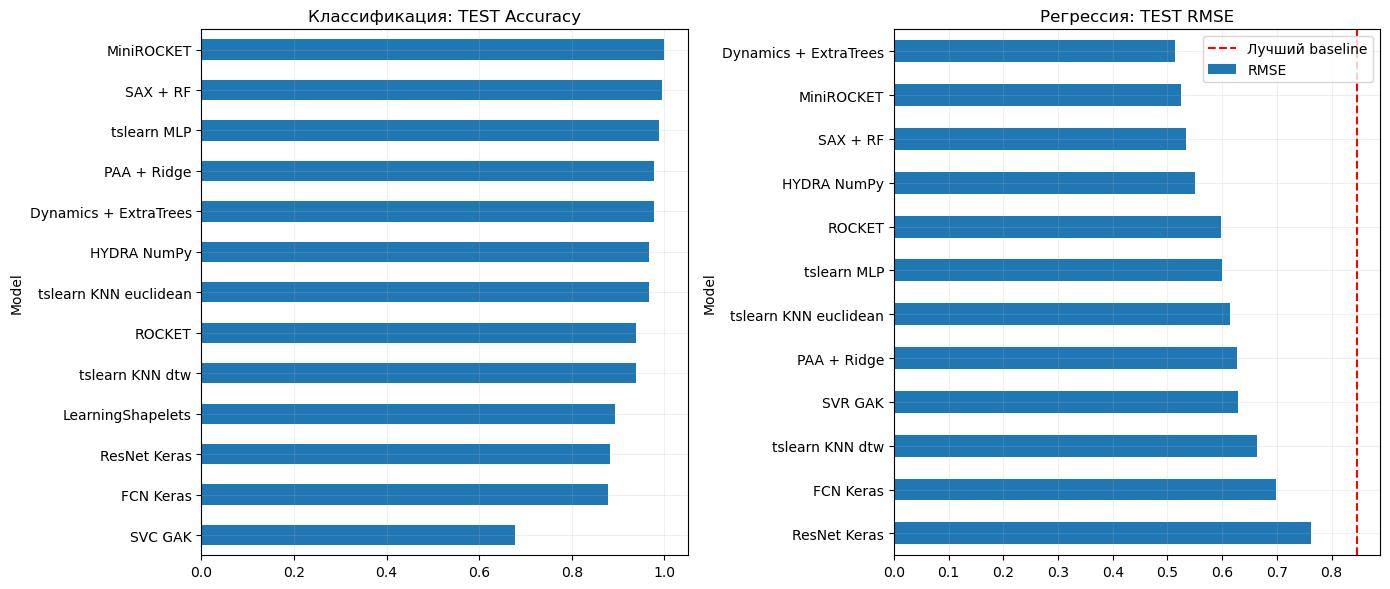

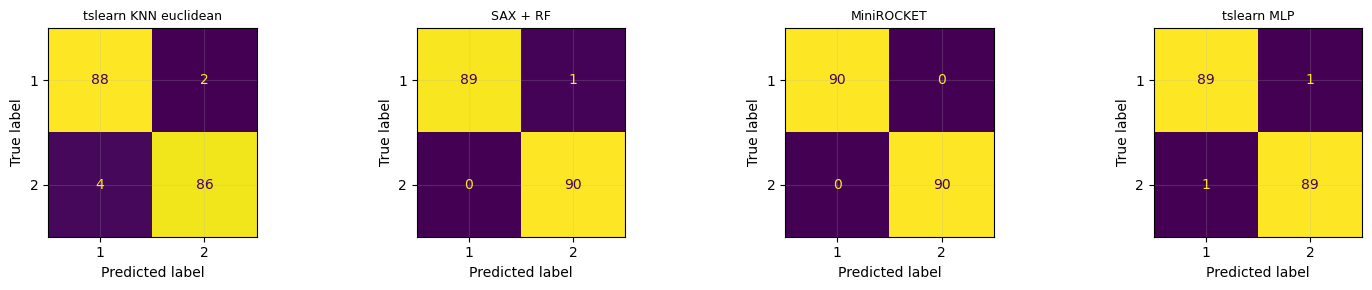

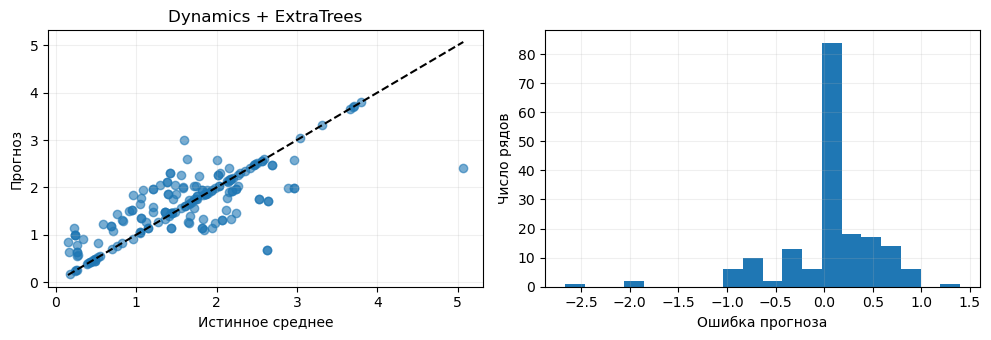

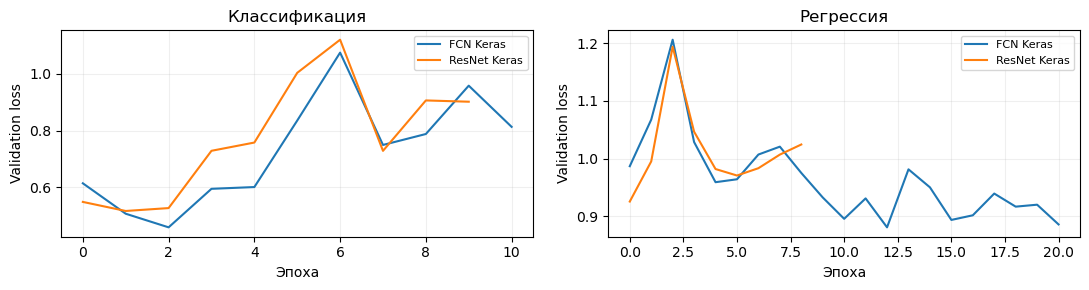

## Выводы

На TEST наибольшая Accuracy у MiniROCKET: 1.000, Macro F1 1.000

Минимальная RMSE у Dynamics + ExtraTrees: 0.5146, MAE 0.3188, R² 0.628, ошибка ниже лучшего baseline (0.8462)

Это описательное сравнение на 180 тестовых рядах, конфигурации и число эпох выбирались на отдельной части TRAIN

Случайные свертки учитывают локальную форму, а признаки уровня и последних входных измерений особенно полезны для прогноза среднего скрытого участка

Отсутствие полной z-нормализации проверено численно, но сведения о всей исходной обработке архива ограничены, дополнительные преобразования обучаются только на доступной части TRAIN

In [12]:
results = pd.DataFrame(rows)
assert results.groupby(['Family','Task']).size().min() >= 3
classification = results[results.Task=='classification'].sort_values(['Accuracy','Macro F1'],ascending=False)
regression = results[results.Task=='regression'].sort_values('RMSE')
display(classification[['Family','Model','Library','Config','Accuracy','Macro F1','Validation score']].round(4))
display(regression[['Family','Model','Library','Config','MAE','RMSE','R2','Validation score']].round(4))
display(results.groupby(['Family','Task']).size().rename('Обучено моделей').to_frame())
fig, axes = plt.subplots(1,2,figsize=(14,6))
classification.set_index('Model')['Accuracy'].sort_values().plot.barh(ax=axes[0],xlim=(0,1.05),title='Классификация: TEST Accuracy')
regression.set_index('Model')['RMSE'].sort_values(ascending=False).plot.barh(ax=axes[1],title='Регрессия: TEST RMSE')
axes[1].axvline(baseline_table.RMSE.min(),color='red',linestyle='--',label='Лучший baseline')
axes[1].legend()
plt.tight_layout()
plt.show()
# Лучшие по validation, чтобы выбор графиков не превращался в подбор по TEST
selected = results[results.Task=='classification'].sort_values('Validation score',ascending=False).groupby('Family',sort=False).head(1)
fig, axes = plt.subplots(1,4,figsize=(15,3))
for ax, (_,row) in zip(axes,selected.iterrows()):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[('classification',row.Model)],ax=ax,colorbar=False)
    ax.set_title(row.Model,fontsize=9)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
best_reg_val = regression.sort_values('Validation score').iloc[0]
pred = predictions[('regression',best_reg_val.Model)]
axes[0].scatter(yr_test,pred,alpha=.6)
limits = [min(yr_test.min(),pred.min()),max(yr_test.max(),pred.max())]
axes[0].plot(limits,limits,'k--')
axes[0].set(xlabel='Истинное среднее',ylabel='Прогноз',title=best_reg_val.Model)
axes[1].hist(pred-yr_test,bins=20)
axes[1].set(xlabel='Ошибка прогноза',ylabel='Число рядов')
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,3))
for (task,name),h in histories.items():
    ax = axes[0 if task=='classification' else 1]
    ax.plot(h['val_loss'],label=name)
for ax,title in zip(axes,['Классификация','Регрессия']):
    ax.set(title=title,xlabel='Эпоха',ylabel='Validation loss')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
out = ROOT/'outputs'/LAB_NAME
out.mkdir(parents=True,exist_ok=True)
results.to_csv(out/'metrics.csv',index=False)
pd.DataFrame(validation_rows).to_csv(out/'validation.csv',index=False)
baseline_table.to_csv(out/'baselines.csv',index=False)
import json, hashlib
split_spec = {'seed':SEED,'fit_indices':fit_idx.tolist(),'validation_indices':val_idx.tolist(),
    'regression_input':120,'regression_target':'mean_last_24',
    'train_sha256':hashlib.sha256((DATA/'PowerCons_TRAIN.txt').read_bytes()).hexdigest(),
    'test_sha256':hashlib.sha256((DATA/'PowerCons_TEST.txt').read_bytes()).hexdigest()}
(out/'split.json').write_text(json.dumps(split_spec,indent=2),encoding='utf-8')
np.savez_compressed(out/'predictions.npz',**{f'{task}__{name}':p for (task,name),p in predictions.items()})
best_c, best_r = classification.iloc[0],regression.iloc[0]
baseline_rmse = baseline_table.RMSE.min()
comparison = 'ниже' if best_r.RMSE < baseline_rmse else 'выше или равна'
display(Markdown(f"## Выводы\n\nНа TEST наибольшая Accuracy у {best_c.Model}: {best_c.Accuracy:.3f}, "
    f"Macro F1 {best_c['Macro F1']:.3f}\n\n"
    f"Минимальная RMSE у {best_r.Model}: {best_r.RMSE:.4f}, MAE {best_r.MAE:.4f}, R² {best_r.R2:.3f}, "
    f"ошибка {comparison} лучшего baseline ({baseline_rmse:.4f})\n\n"
    "Это описательное сравнение на 180 тестовых рядах, конфигурации и число эпох выбирались на отдельной части TRAIN\n\n"
    "Случайные свертки учитывают локальную форму, а признаки уровня и последних входных измерений особенно полезны для прогноза среднего скрытого участка\n\n"
    "Отсутствие полной z-нормализации проверено численно, но сведения о всей исходной обработке архива ограничены, дополнительные преобразования обучаются только на доступной части TRAIN"))

## Сопоставление с aeon

Сравниваем одинаковые официальные TRAIN/TEST, одинаковую регрессионную цель и индексы валидации, общие модели служат контролем, поэтому совпадение их метрик ожидаемо

Сопоставление выполняется при наличии сохраненных результатов лабораторной 14, остальные вычисления ноутбука от них не зависят

,Работа,Семейство,Задача,Модель,Accuracy,RMSE
0,14: aeon,Convolution,classification,MiniROCKET,1.0000,NaN
1,14: aeon,Convolution,regression,MiniROCKET,NaN,0.5254
2,14: aeon,Deep Learning,classification,MLP Keras,0.9889,NaN
3,14: aeon,Deep Learning,regression,FCN Keras,NaN,0.6976
4,14: aeon,Distance,classification,KNN euclidean,0.9778,NaN
5,14: aeon,Distance,regression,KNN euclidean,NaN,0.6137
6,14: aeon,Feature,classification,Dynamics + RF,0.9889,NaN
7,14: aeon,Feature,regression,Dynamics + ExtraTrees,NaN,0.5146
8,16: tslearn,Convolution,classification,MiniROCKET,1.0000,NaN
9,16: tslearn,Convolution,regression,MiniROCKET,NaN,0.5254


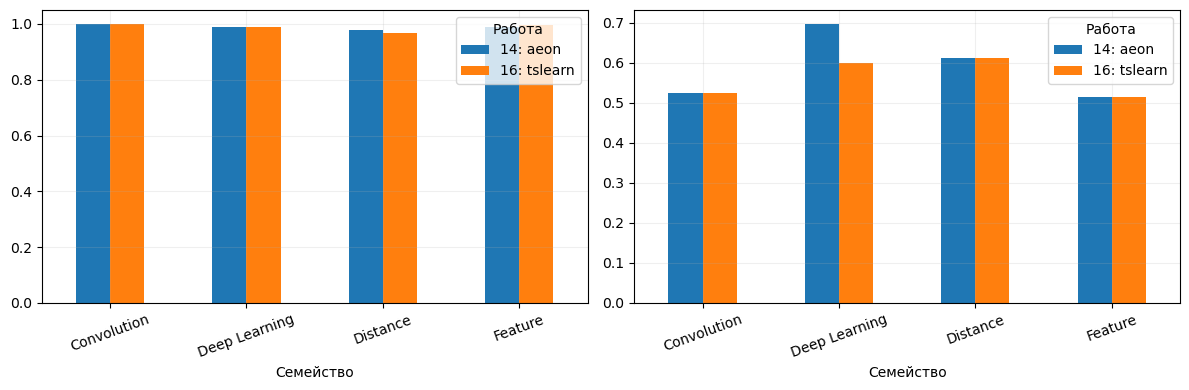

Общие ROCKET, MiniROCKET, HYDRA и Extra Trees обучаются заново по одинаковому протоколу, поэтому их результаты позволяют проверить воспроизводимость

Различия между работами относятся к конкретным моделям и признакам, а не доказывают превосходство одной библиотеки в целом

In [13]:
prior = ROOT/'outputs'/'lab14'
if (prior/'metrics.csv').exists() and (prior/'split.json').exists():
    old_split = json.loads((prior/'split.json').read_text(encoding='utf-8'))
    assert old_split == split_spec, 'Сравнение невозможно: данные или разбиения различаются'
    old = pd.read_csv(prior/'metrics.csv')
    joined = pd.concat([old.assign(Lab='14: aeon'),results.assign(Lab='16: tslearn')],ignore_index=True)
    best_rows = []
    for (lab,family,task),group in joined.groupby(['Lab','Family','Task']):
        best = group.sort_values('Accuracy',ascending=False).iloc[0] if task=='classification' else group.sort_values('RMSE').iloc[0]
        best_rows.append({'Работа':lab,'Семейство':family,'Задача':task,'Модель':best.Model,
            'Accuracy':best.Accuracy,'RMSE':best.RMSE})
    compare = pd.DataFrame(best_rows)
    display(compare.round(4))
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    compare[compare['Задача']=='classification'].pivot(index='Семейство',columns='Работа',values='Accuracy').plot.bar(ax=axes[0],rot=20,ylim=(0,1.05))
    compare[compare['Задача']=='regression'].pivot(index='Семейство',columns='Работа',values='RMSE').plot.bar(ax=axes[1],rot=20)
    plt.tight_layout()
    plt.show()
    compare.to_csv(out/'comparison_lab14.csv',index=False)
    display(Markdown('Общие ROCKET, MiniROCKET, HYDRA и Extra Trees обучаются заново по одинаковому протоколу, поэтому их результаты позволяют проверить воспроизводимость\n\nРазличия между работами относятся к конкретным моделям и признакам, а не доказывают превосходство одной библиотеки в целом'))
else:
    display(Markdown('Результатов лабораторной 14 рядом нет, собственные модели обучены и оценены независимо, таблица сравнения появится после отдельного запуска лабораторной 14'))